This is a hand implemented notebook to understand each and everything and never leave a thing as a blackbox.


In [1]:
import hashlib
import math
import pickle
import ssl
import tarfile
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset





SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")




# 3. Local debug switch (True = tiny fast runs on Mac; False = full 240-epoch run on GPU)
FAST_DEV_RUN = True
# 4. Paths (works whether Jupyter starts in ML-Project/ or ML-Project/notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"
CKPT_ROOT = PROJECT_ROOT / "checkpoints"
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {DEVICE}")
print(f"Project root    : {PROJECT_ROOT}")
print(f"FAST_DEV_RUN    : {FAST_DEV_RUN}")



Using device: mps
PyTorch version : 2.15.0
Using device    : mps
Project root    : /Users/sufyan.siddiqui/ML-Project
FAST_DEV_RUN    : True


In [2]:
CIFAR100_URL = "https://huggingface.co/datasets/nakroy/cifar100-python/resolve/main/cifar-100-python.tar.gz"
CIFAR100_MD5 = "eb9058c3a382ffc7106e4002c42a8d85"


def ensure_cifar100_downloaded(data_root: Path = DATA_ROOT) -> Path:
    cifar_dir = data_root / "cifar-100-python"
    if all((cifar_dir / name).exists() for name in ("train", "test", "meta")):
        print(f"Found existing CIFAR-100 files at: {cifar_dir}")
        return cifar_dir

    data_root.mkdir(parents=True, exist_ok=True)
    tar_path = data_root / "cifar-100-python.tar.gz"

    print("Downloading CIFAR-100 (~161 MB)...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()

    req = urllib.request.Request(CIFAR100_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        out.write(resp.read())

    md5 = hashlib.md5(tar_path.read_bytes()).hexdigest()
    assert md5 == CIFAR100_MD5, f"MD5 mismatch! Expected {CIFAR100_MD5}, got {md5}"

    print("Extracting archive...")
    with tarfile.open(tar_path, "r:gz") as tar:
        tar.extractall(path=data_root)
    print(f"Extracted CIFAR-100 to: {cifar_dir}")
    return cifar_dir


CIFAR_DIR = ensure_cifar100_downloaded()

Found existing CIFAR-100 files at: /Users/sufyan.siddiqui/ML-Project/data/cifar-100-python


In [3]:
def unpickle_file(path: Path) -> dict:
    with path.open("rb") as f:
        return pickle.load(f, encoding="bytes")

raw_train = unpickle_file(CIFAR_DIR / "train")
raw_test = unpickle_file(CIFAR_DIR / "test")
raw_meta = unpickle_file(CIFAR_DIR/ "meta")


for dataset, data in {"train": raw_train, "test": raw_test, "meta": raw_meta}.items():
    print(f"Keys in {dataset} dataset: {list(data.keys())}")
    if b"data" in data:
        print(f"  Number of samples : {len(data[b'data'])}")
        print(f"  Shape of data     : {data[b'data'].shape}")
        print(f"  Array type / dtype: {type(data[b'data'])}, {data[b'data'].dtype}")

Keys in train dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 50000
  Shape of data     : (50000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in test dataset: [b'filenames', b'batch_label', b'fine_labels', b'coarse_labels', b'data']
  Number of samples : 10000
  Shape of data     : (10000, 3072)
  Array type / dtype: <class 'numpy.ndarray'>, uint8
Keys in meta dataset: [b'fine_label_names', b'coarse_label_names']


In [4]:
train_images = raw_train[b"data"].reshape(-1,3,32,32).transpose(0,2,3,1)
print(f"Shape of train images after reshaping and transposing: {train_images.shape}")
train_labels = np.array(raw_train[b"fine_labels"], dtype = np.int64)
train_coarse = np.array(raw_train[b"coarse_labels"], dtype = np.int64)
print(f"Shape of train labels: {train_labels.shape}")
print(f"Shape of train coarse labels: {train_coarse.shape}")
print(f"First 10 train labels: {train_labels[:10]}")
print(f"First 10 train coarse labels: {train_coarse[:10]}")
print(f"Unique train labels: {np.unique(train_labels)}")
print(f"Unique train coarse labels: {np.unique(train_coarse)}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")
print(f"Number of unique train coarse labels: {len(np.unique(train_coarse))}")
print(f"Number of unique train labels: {len(np.unique(train_labels))}")

Shape of train images after reshaping and transposing: (50000, 32, 32, 3)
Shape of train labels: (50000,)
Shape of train coarse labels: (50000,)
First 10 train labels: [19 29  0 11  1 86 90 28 23 31]
First 10 train coarse labels: [11 15  4 14  1  5 18  3 10 11]
Unique train labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique train coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique train labels: 100
Number of unique train coarse labels: 20
Number of unique train labels: 100


In [5]:
test_images = raw_test[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
test_labels = np.array(raw_test[b"fine_labels"], dtype=np.int64)
test_coarse = np.array(raw_test[b"coarse_labels"], dtype=np.int64)
print(f"Shape of test images after reshaping and transposing: {test_images.shape}")
print(f"Shape of test labels: {test_labels.shape}")
print(f"Shape of test coarse labels: {test_coarse.shape}")
print(f"First 10 test labels: {test_labels[:10]}")
print(f"First 10 test coarse labels: {test_coarse[:10]}")
print(f"Unique test labels: {np.unique(test_labels)}")
print(f"Unique test coarse labels: {np.unique(test_coarse)}")
print(f"Number of unique test labels: {len(np.unique(test_labels))}")
print(f"Number of unique test coarse labels: {len(np.unique(test_coarse))}")


Shape of test images after reshaping and transposing: (10000, 32, 32, 3)
Shape of test labels: (10000,)
Shape of test coarse labels: (10000,)
First 10 test labels: [49 33 72 51 71 92 15 14 23  0]
First 10 test coarse labels: [10 10  0  4 10  2 11  7 10  4]
Unique test labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71
 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95
 96 97 98 99]
Unique test coarse labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Number of unique test labels: 100
Number of unique test coarse labels: 20


In [6]:
fine_names = [x.decode("utf-8") for x in raw_meta[b"fine_label_names"]]
coarse_names = [x.decode("utf-8") for x in raw_meta[b"coarse_label_names"]]
print(f"Number of fine label names: {len(fine_names)}")
print(f"Number of coarse label names: {len(coarse_names)}")
print(f"First 10 fine label names: {fine_names[:10]}")
print(f"First 10 coarse label names: {coarse_names[:10]}")
print(f"Unique fine label names: {np.unique(fine_names)}")
print(f"Unique coarse label names: {np.unique(coarse_names)}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")
print(f"Number of unique coarse label names: {len(np.unique(coarse_names))}")
print(f"Number of unique fine label names: {len(np.unique(fine_names))}")

Number of fine label names: 100
Number of coarse label names: 20
First 10 fine label names: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 'bicycle', 'bottle']
First 10 coarse label names: ['aquatic_mammals', 'fish', 'flowers', 'food_containers', 'fruit_and_vegetables', 'household_electrical_devices', 'household_furniture', 'insects', 'large_carnivores', 'large_man-made_outdoor_things']
Unique fine label names: ['apple' 'aquarium_fish' 'baby' 'bear' 'beaver' 'bed' 'bee' 'beetle'
 'bicycle' 'bottle' 'bowl' 'boy' 'bridge' 'bus' 'butterfly' 'camel' 'can'
 'castle' 'caterpillar' 'cattle' 'chair' 'chimpanzee' 'clock' 'cloud'
 'cockroach' 'couch' 'crab' 'crocodile' 'cup' 'dinosaur' 'dolphin'
 'elephant' 'flatfish' 'forest' 'fox' 'girl' 'hamster' 'house' 'kangaroo'
 'keyboard' 'lamp' 'lawn_mower' 'leopard' 'lion' 'lizard' 'lobster' 'man'
 'maple_tree' 'motorcycle' 'mountain' 'mouse' 'mushroom' 'oak_tree'
 'orange' 'orchid' 'otter' 'palm_tree' 'pear' 'pickup_truck

In [7]:
print(f"train_images : {train_images.shape}, dtype={train_images.dtype}, range=[{train_images.min()}, {train_images.max()}]")
print(f"test_images  : {test_images.shape}, dtype={test_images.dtype}")
print(f"Classes      : {len(fine_names)} fine classes grouped into {len(coarse_names)} superclasses")

train_images : (50000, 32, 32, 3), dtype=uint8, range=[0, 255]
test_images  : (10000, 32, 32, 3), dtype=uint8
Classes      : 100 fine classes grouped into 20 superclasses


Plotting image 1 of 10
Plotting image 2 of 10
Plotting image 3 of 10
Plotting image 4 of 10
Plotting image 5 of 10
Plotting image 6 of 10
Plotting image 7 of 10
Plotting image 8 of 10
Plotting image 9 of 10
Plotting image 10 of 10


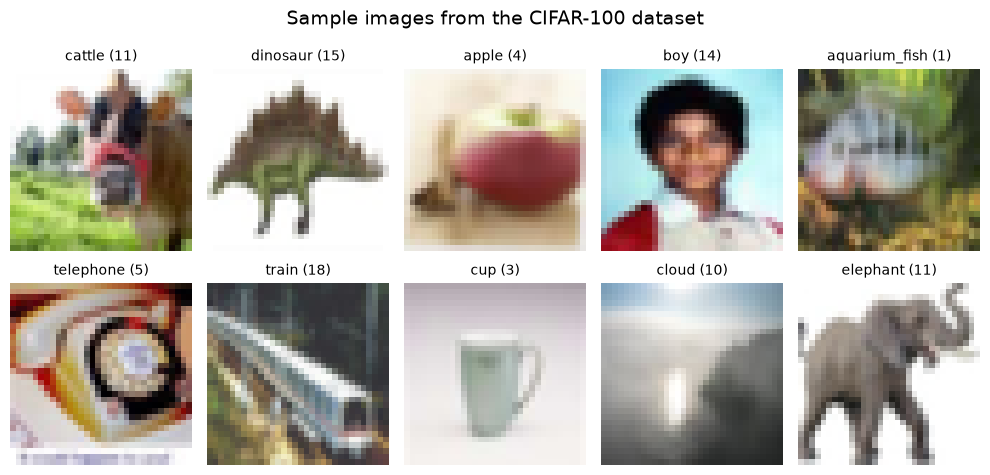

In [8]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(10, 5))
# print(f"figures {fig}, axes {axes}")
for idx, ax in enumerate(axes.flat):
    print(f"Plotting image {idx+1} of 10")
    ax.imshow(train_images[idx])
    ax.set_title(f"{fine_names[train_labels[idx]]} ({train_coarse[idx]})", fontsize=10)
    ax.axis("off")


plt.suptitle("Sample images from the CIFAR-100 dataset", fontsize=14)
plt.tight_layout()
plt.show()

Pipeline


In [9]:
scaled = train_images / 255.0  # shape: (50000, 32, 32, 3)
print("Computed mean :", scaled.mean(axis=(0, 1, 2)).round(4))
print("Computed std  :", scaled.std(axis=(0, 1, 2)).round(4))

Computed mean : [0.5071 0.4865 0.4409]
Computed std  : [0.2673 0.2564 0.2762]


In [10]:
# Exact RGB channel mean and std from the DKD / mdistiller CIFAR-100 recipe
CIFAR100_MEAN = np.array([0.5071, 0.4867, 0.4408], dtype=np.float32)
CIFAR100_STD  = np.array([0.2675, 0.2565, 0.2761], dtype=np.float32)


def preprocess_train(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32."""
    # print("Raw (32, 32, 3) uint8 -> augmented, normalized (3, 32, 32) float32.")
    # 1. Pad 4 zeros on top/bottom and left/right -> shape becomes (40, 40, 3)
    padded = np.pad(img_hwc, ((4, 4), (4, 4), (0, 0)), mode="constant", constant_values=0)
    # 2. Pick a random 32x32 window (top and left can each be 0..8)
    top = np.random.randint(0, 9)
    left = np.random.randint(0, 9)
    cropped = padded[top : top + 32, left : left + 32]
    # 3. 50% chance left-right mirror flip
    if np.random.rand() < 0.5:
        cropped = cropped[:, ::-1, :]
    
    # 4. Scale to [0, 1], normalize per RGB channel, and transpose HWC -> CHW
    normed = (cropped.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [11]:
def preprocess_eval(img_hwc: np.ndarray) -> np.ndarray:
    """Raw (32, 32, 3) uint8 -> clean normalized (3, 32, 32) float32 (no crop, no flip)."""
    normed = (img_hwc.astype(np.float32) / 255.0 - CIFAR100_MEAN) / CIFAR100_STD
    return np.ascontiguousarray(normed.transpose(2, 0, 1))

In [12]:

def unnormalize_for_plot(chw: np.ndarray) -> np.ndarray:
    """Undo normalization and CHW -> HWC just so Matplotlib can display a tensor."""
    hwc = chw.transpose(1, 2, 0) * CIFAR100_STD + CIFAR100_MEAN
    return np.clip(hwc, 0.0, 1.0)

In [13]:
# Sanity check on image 0 ('cattle')
sample_eval = preprocess_eval(train_images[0])
print(f"Output shape : {sample_eval.shape}, dtype={sample_eval.dtype}")
print(f"Value range  : min={sample_eval.min():.2f}, max={sample_eval.max():.2f}, mean={sample_eval.mean():.2f}")


Output shape : (3, 32, 32), dtype=float32
Value range  : min=-1.79, max=2.03, mean=0.24


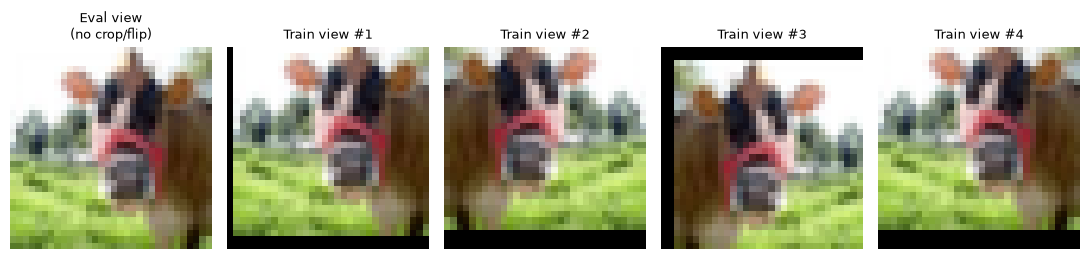

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.5))
axes[0].imshow(unnormalize_for_plot(sample_eval))
axes[0].set_title("Eval view\n(no crop/flip)", fontsize=9)
axes[0].axis("off")
for i in range(1, 5):
    aug = preprocess_train(train_images[0])
    axes[i].imshow(unnormalize_for_plot(aug))
    axes[i].set_title(f"Train view #{i}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [15]:
class SimpleCIFAR100(Dataset):
    def __init__(self, images:np.ndarray, labels: np.ndarray, is_train:bool):
        self.images = images
        self.labels = labels
        self.is_train = is_train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx: int):
        raw_img = self.images[idx]
        chw = preprocess_train(raw_img) if self.is_train else preprocess_eval(raw_img)
        return torch.from_numpy(chw), int(self.labels[idx])



BATCH_SIZE = 64
train_dataset = SimpleCIFAR100(train_images, train_labels, is_train=True)
test_dataset = SimpleCIFAR100(test_images, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

sample_batch_x, sample_batch_y = next(iter(train_loader))
print(f"Train batches per epoch : {len(train_loader)} (50,000 / 64)")
print(f"Test batches            : {len(test_loader)} (10,000 / 128)")
print(f"One batch X shape       : {sample_batch_x.shape}, dtype={sample_batch_x.dtype}")
print(f"One batch Y shape       : {sample_batch_y.shape}, dtype={sample_batch_y.dtype}")

Train batches per epoch : 782 (50,000 / 64)
Test batches            : 157 (10,000 / 128)
One batch X shape       : torch.Size([64, 3, 32, 32]), dtype=torch.float32
One batch Y shape       : torch.Size([64]), dtype=torch.int64


In [16]:
TEACHER_TAR_URL = "https://github.com/megvii-research/mdistiller/releases/download/checkpoints/cifar_teachers.tar"
TEACHER_CKPT_PATH = CKPT_ROOT / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"


def ensure_teacher_ckpt(ckpt_root: Path = CKPT_ROOT) -> Path:
    ckpt_path = ckpt_root / "cifar_teachers" / "resnet32x4_vanilla" / "ckpt_epoch_240.pth"
    if ckpt_path.exists():
        print(f"Found teacher checkpoint at: {ckpt_path}")
        return ckpt_path
    ckpt_root.mkdir(parents=True, exist_ok=True)
    tar_path = ckpt_root / "cifar_teachers.tar"
    print("Downloading cifar_teachers.tar...")
    try:
        import certifi
        ssl_ctx = ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        ssl_ctx = ssl.create_default_context()
    req = urllib.request.Request(TEACHER_TAR_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, context=ssl_ctx) as resp, tar_path.open("wb") as out:
        while chunk := resp.read(1024 * 1024):
            out.write(chunk)
    with tarfile.open(tar_path, "r") as tar:
        members = [m for m in tar.getmembers() if m.name.startswith("cifar_teachers/resnet32x4_vanilla/")]
        tar.extractall(ckpt_root, members=members)
    tar_path.unlink(missing_ok=True)
    return ckpt_path

In [17]:
ckpt_file = ensure_teacher_ckpt()
print(f"Teacher checkpoint file: {ckpt_file}")


Found teacher checkpoint at: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth
Teacher checkpoint file: /Users/sufyan.siddiqui/ML-Project/checkpoints/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth


In [18]:
raw_ckpt = torch.load(ckpt_file, map_location="cpu", weights_only=False)

print("Top-level keys in .pth:", list(raw_ckpt.keys()))
print("First 5 keys:", list(raw_ckpt.keys())[:5])
print("Last 5 keys:", list(raw_ckpt.keys())[-5:])

teacher_state = raw_ckpt["model"]

print("Total tensors in model: ", len(teacher_state))

print("\nFirst 12 Parameter Tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[:12]:
    print(f"{name:>35} : {tensor.shape}")



print("\nLast 4 parameter tensors (name -> shape):")
for name, tensor in list(teacher_state.items())[-4:]:
    print(f"  {name:35s} -> {tuple(tensor.shape)}")










Top-level keys in .pth: ['epoch', 'model', 'accuracy', 'optimizer']
First 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Last 5 keys: ['epoch', 'model', 'accuracy', 'optimizer']
Total tensors in model:  172

First 12 Parameter Tensors (name -> shape):
                       conv1.weight : torch.Size([32, 3, 3, 3])
                         bn1.weight : torch.Size([32])
                           bn1.bias : torch.Size([32])
                   bn1.running_mean : torch.Size([32])
                    bn1.running_var : torch.Size([32])
              layer1.0.conv1.weight : torch.Size([64, 32, 3, 3])
                layer1.0.bn1.weight : torch.Size([64])
                  layer1.0.bn1.bias : torch.Size([64])
          layer1.0.bn1.running_mean : torch.Size([64])
           layer1.0.bn1.running_var : torch.Size([64])
              layer1.0.conv2.weight : torch.Size([64, 64, 3, 3])
                layer1.0.bn2.weight : torch.Size([64])

Last 4 parameter tensors (name -> shape):
  layer3.4.

In [19]:
class BasicBlock(nn.Module):
     """Two 3x3 conv layers + skip connection: out = ReLU(F(x) + shortcut(x))."""

     def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        downsample: nn.Module | None = None,
     ):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_channels)
        self.relu  = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_channels)
        self.downsample = downsample

     def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(residual)

        out = out +residual
        out = self.relu(out) # ReLU after residual addition
        return out

# Sanity check 1: Identity shortcut (64 -> 64 channels, 32x32 -> 32x32)

x_same = torch.randn(2, 64, 32, 32)
block_identity = BasicBlock(in_channels=64, out_channels=64, stride=1)
print(f"Output shape of identity block: {block_identity(x_same).shape}")


# Sanity check 2: Downsample shortcut (64 -> 128 channels, 32x32 -> 16x16 via stride=2)
proj = nn.Sequential(
    nn.Conv2d(64, 128, kernel_size=1, stride=2, bias=False),
    nn.BatchNorm2d(128)
)
block_downsample = BasicBlock(in_channels=64, out_channels=128, stride=2, downsample=proj)
print(f"Output shape of downsample block: {block_downsample(x_same).shape}")




Output shape of identity block: torch.Size([2, 64, 32, 32])
Output shape of downsample block: torch.Size([2, 128, 16, 16])


In [21]:
def make_shortcut(in_ch: int, out_ch: int, stride: int) -> nn.Sequential:
    """1x1 conv + BN used whenever a block changes channels or spatial size."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
        nn.BatchNorm2d(out_ch),
    )


class StudentResNet8x4(nn.Module):
    def __init__(self, num_classes: int=100):

        super().__init__()

        #1 Entry stem: (B, 3, 32, 32) -> (B, 32, 32, 32)

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.relu  = nn.ReLU(inplace=True)

        #2. 3 Stages, just 1 BasicBlock in each stage!!

        self.layer1 = nn.Sequential(
    
            BasicBlock(in_channels=32, out_channels=64, stride=1, downsample=make_shortcut(32, 64, stride=1)),
        )

        self.layer2 = nn.Sequential(
            BasicBlock(64, 128, stride=2, downsample=make_shortcut(64, 128, stride=2))
        )
        self.layer3 = nn.Sequential(
            BasicBlock(128, 256, stride=2, downsample=make_shortcut(128, 256, stride=2))
        )

        # 3. Classifier head: (B, 256, 8, 8) -> (B, 256, 1, 1) -> (B, 100)

        self.avgpool = nn.AvgPool2d(kernel_size=8)
        self.fc      = nn.Linear(256, num_classes)


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.bn1(self.conv1(x)))  # (B, 32, 32, 32)
        x = self.layer1(x)                      # (B, 64, 32, 32)
        x = self.layer2(x)                      # (B, 128, 16, 16)
        x = self.layer3(x)                      # (B, 256, 8, 8)
        x = self.avgpool(x)                     # (B, 256, 1, 1)
        x = torch.flatten(x, start_dim=1)       # (B, 256)
        return self.fc(x)                       # (B, 100)


student_test = StudentResNet8x4()
print(f"Student model architecture: {student_test}")


print("Student output shape :", student_test(torch.randn(4, 3, 32, 32)).shape)
print("Student parameters   :", f"{sum(p.numel() for p in student_test.parameters()):,}")

Student model architecture: StudentResNet8x4(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (downsample): Sequential(
        (0): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
  )
  (layer2): Sequential(
    (0): Bas

In [22]:

class TeacherResNet32x4(nn.Module):
    def __init__(self, num_classes: int = 100):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.relu  = nn.ReLU(inplace=True)

        # Each stage has 1 transition block + 4 identity blocks = 5 blocks per stage
        self.layer1 = nn.Sequential(
            BasicBlock(32, 64, stride=1, downsample=make_shortcut(32, 64, stride=1)),
            *[BasicBlock(64, 64) for _ in range(4)],
        )
        self.layer2 = nn.Sequential(
            BasicBlock(64, 128, stride=2, downsample=make_shortcut(64, 128, stride=2)),
            *[BasicBlock(128, 128) for _ in range(4)],
        )
        self.layer3 = nn.Sequential(
            BasicBlock(128, 256, stride=2, downsample=make_shortcut(128, 256, stride=2)),
            *[BasicBlock(256, 256) for _ in range(4)],
        )

        self.avgpool = nn.AvgPool2d(kernel_size=8)
        self.fc      = nn.Linear(256, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.avgpool(x)
        x = torch.flatten(x, start_dim=1)
        return self.fc(x)


# Instantiate Teacher, load Megvii's 172 tensors with strict=True, and freeze it!
teacher = TeacherResNet32x4().to(DEVICE)
load_result = teacher.load_state_dict(teacher_state, strict=True)
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

t_params = sum(p.numel() for p in teacher.parameters())
s_params = sum(p.numel() for p in student_test.parameters())
print("load_state_dict result :", load_result)
print(f"Teacher parameters     : {t_params:,} ({t_params / s_params:.2f}x larger than Student)")

load_state_dict result : <All keys matched successfully>
Teacher parameters     : 7,433,860 (6.03x larger than Student)


In [23]:
@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    """Returns (average_ce_loss, top1_accuracy_percent) on the given DataLoader."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(images)
        loss = F.cross_entropy(logits, labels)

        preds = logits.argmax(dim=1)
        bs = labels.size(0)
        total_loss += loss.item() * bs
        total_correct += (preds == labels).sum().item()
        total_samples += bs

    return total_loss / total_samples, 100.0 * total_correct / total_samples


teacher_loss, teacher_acc = evaluate_model(teacher, test_loader)
print(f"Teacher Test Loss     : {teacher_loss:.4f}")
print(f"Teacher Test Accuracy : {teacher_acc:.2f}% (DKD paper reports 79.42%)")

Teacher Test Loss     : 0.8833
Teacher Test Accuracy : 79.42% (DKD paper reports 79.42%)


Evaluate Teacher & Plot Its 2D Feature Space + Decision Boundary

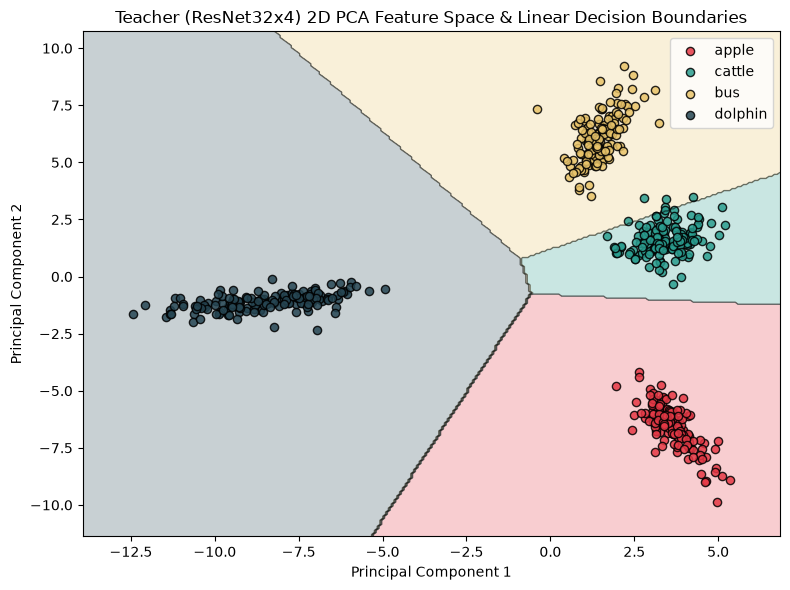

In [ ]:
# Pick 4 clear classes from our training set (150 images per class = 600 points)
chosen_names = ["apple", "cattle", "bus", "dolphin"]
chosen_ids = [fine_names.index(name) for name in chosen_names]

print(f"Chosen classes: {chosen_names}")

sub_imgs, sub_labels = [], []
for cid in chosen_ids:
    idxs = np.where(train_labels == cid)[0][:150]  #what is that? could we use all images of a class? 
    for i in idxs:
        sub_imgs.append(preprocess_eval(train_images[i]))
        sub_labels.append(cid)

x_sub = torch.tensor(np.array(sub_imgs), device=DEVICE)
y_sub = np.array(sub_labels)

# 1. Extract the Teacher's 256-dim penultimate features (right before teacher.fc)
with torch.no_grad():
    h = teacher.relu(teacher.bn1(teacher.conv1(x_sub)))
    h = teacher.layer3(teacher.layer2(teacher.layer1(h)))
    feats_256 = torch.flatten(teacher.avgpool(h), 1).cpu()  # shape: (600, 256)
    #what the heck happened here? 

# 2. Project 256-D -> 2-D via PCA (using SVD on centered features)
mean_256 = feats_256.mean(dim=0, keepdim=True)
centered = feats_256 - mean_256
_, _, Vt = torch.linalg.svd(centered, full_matrices=False)
W_pca = Vt[:2].T                      # (256, 2) top-2 principal directions
pts_2d = (centered @ W_pca).numpy()   # (600, 2) coordinates in 2D!

# 3. Build a 2D grid, map each (u, v) back to 256-D, and ask teacher.fc to classify it!
pad = 1.5
u_grid = np.linspace(pts_2d[:, 0].min() - pad, pts_2d[:, 0].max() + pad, 250)
v_grid = np.linspace(pts_2d[:, 1].min() - pad, pts_2d[:, 1].max() + pad, 250)
UU, VV = np.meshgrid(u_grid, v_grid)
grid_2d = torch.tensor(np.c_[UU.ravel(), VV.ravel()], dtype=torch.float32)

grid_256 = (grid_2d @ W_pca.T + mean_256).to(DEVICE)
with torch.no_grad():
    # Restrict decision regions to our 4 chosen classes
    logits_4 = teacher.fc(grid_256)[:, chosen_ids].cpu().numpy()
region_idx = logits_4.argmax(axis=1).reshape(UU.shape)

# 4. Plot decision regions + real training samples
colors = ["#e63946", "#2a9d8f", "#e9c46a", "#264653"]
plt.figure(figsize=(8, 6))
plt.contourf(UU, VV, region_idx, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], colors=colors, alpha=0.25)
plt.contour(UU, VV, region_idx, levels=[0.5, 1.5, 2.5], colors="k", linewidths=1.0, alpha=0.5)

for k, (cid, cname) in enumerate(zip(chosen_ids, chosen_names)):
    mask = y_sub == cid
    plt.scatter(pts_2d[mask, 0], pts_2d[mask, 1], c=colors[k], label=cname, edgecolors="k", s=35, alpha=0.85)

plt.title("Teacher (ResNet32x4) 2D PCA Feature Space & Linear Decision Boundaries")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

## Stage 4: Classical Knowledge Distillation (`kd_loss`) & What Temperature $T = 4.0$ Does

Suppose we pass one batch of 64 images into both networks:
- `logits_t = teacher(images)` $\rightarrow$ shape `(64, 100)` raw scores
- `logits_s = student(images)` $\rightarrow$ shape `(64, 100)` raw scores

If we take normal softmax ($T = 1.0$) on a confident Teacher (`logits_t`), the Teacher puts `0.999` on `cattle` and `0.00001` on `elephant` — so all the rich inter-class similarity (**"dark knowledge"**) gets squashed near zero.

**Hinton's 2015 fix:** divide logits by Temperature $T = 4.0$ before softmax:

$$p_i = \frac{\exp(z_i / T)}{\sum_{j=1}^{100} \exp(z_j / T)}$$

Dividing by $4$ softens the peaks (`0.999` becomes say `0.55`, `elephant` becomes `0.08`, while unrelated `apple` stays `0.0001`), exposing how visually similar the Teacher thinks the non-target classes are!

Classical KD then measures **KL Divergence** between the Teacher's soft probabilities $p^T$ and the Student's soft probabilities $p^S$, scaled by $T^2$ (multiplying by $T^2 = 16$ compensates for dividing logits by $T$ twice in the backpropagation gradient chain rule):

$$\mathcal{L}_{\text{KD}} = T^2 \cdot \text{KL}(p^T \parallel p^S)$$

In [28]:
def kd_loss(logits_s: torch.Tensor, logits_t: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Classical Hinton KD loss: KL(p_teacher || p_student) * T^2."""
    log_p_s = F.log_softmax(logits_s / T, dim=1)
    p_t     = F.softmax(logits_t / T, dim=1)
    return F.kl_div(log_p_s, p_t, reduction="batchmean") * (T * T)

In [29]:
# Visual check: pass 1 real test image through Teacher and compare T=1.0 vs T=4.0!
one_img, one_label = test_dataset[0]
with torch.no_grad():
    one_logits_t = teacher(one_img.unsqueeze(0).to(DEVICE)).cpu()[0]  # (100,)


p_sharp = F.softmax(one_logits_t / 1.0, dim=0).numpy()
p_soft  = F.softmax(one_logits_t / 4.0, dim=0).numpy()


top5_ids = p_soft.argsort()[::-1][:5]
top5_names = [fine_names[i] for i in top5_ids]

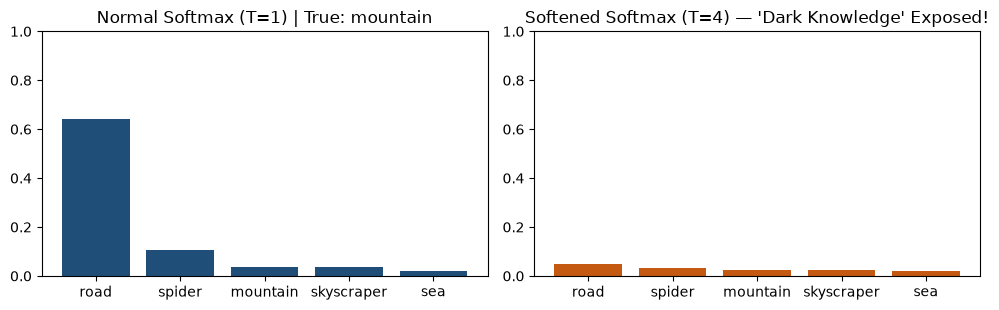

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(top5_names, p_sharp[top5_ids], color="#1f4e79")
axes[0].set_title(f"Normal Softmax (T=1) | True: {fine_names[one_label]}")
axes[0].set_ylim(0, 1.0)
axes[1].bar(top5_names, p_soft[top5_ids], color="#c45911")
axes[1].set_title("Softened Softmax (T=4) — 'Dark Knowledge' Exposed!")
axes[1].set_ylim(0, 1.0)
plt.tight_layout()
plt.show()

In [31]:
student_untrained = StudentResNet8x4().to(DEVICE)

batch_x = sample_batch_x.to(DEVICE)
batch_y = sample_batch_y.to(DEVICE)

with torch.no_grad():
    batch_logits_t = teacher(batch_x)            # (64, 100) trained Teacher scores
batch_logits_s = student_untrained(batch_x)      # (64, 100) fresh untrained Student scores

val_ce = F.cross_entropy(batch_logits_s, batch_y)
val_kd = kd_loss(batch_logits_s, batch_logits_t, T=4.0)

print(f"Untrained Student CE loss : {val_ce.item():.4f} (random guessing over 100 classes is ln(100) = {math.log(100):.4f})")
print(f"Classical KD loss (T=4)   : {val_kd.item():.4f}")

Untrained Student CE loss : 4.6145 (random guessing over 100 classes is ln(100) = 4.6052)
Classical KD loss (T=4)   : 10.6828


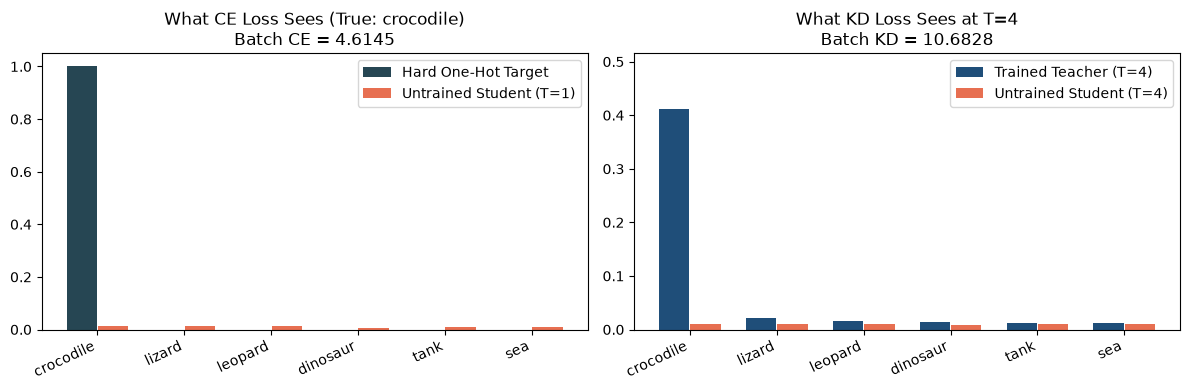

In [32]:
idx_show = 0
true_id = int(batch_y[idx_show].item())

# 1. What Cross-Entropy (CE) compares at T=1: One-hot hard label vs. Student softmax
onehot_target = np.zeros(100)
onehot_target[true_id] = 1.0
p_s_ce = F.softmax(batch_logits_s[idx_show], dim=0).detach().cpu().numpy()

# 2. What Classical KD compares at T=4: Teacher soft probs vs. Student soft probs
p_t_kd = F.softmax(batch_logits_t[idx_show] / 4.0, dim=0).detach().cpu().numpy()
p_s_kd = F.softmax(batch_logits_s[idx_show] / 4.0, dim=0).detach().cpu().numpy()

# Focus on the top-6 classes according to the Teacher so labels are readable
top6 = p_t_kd.argsort()[::-1][:6]
names6 = [fine_names[i] for i in top6]
x_pos = np.arange(len(top6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: Hard-Label Cross-Entropy view
axes[0].bar(x_pos - 0.18, onehot_target[top6], width=0.35, label="Hard One-Hot Target", color="#264653")
axes[0].bar(x_pos + 0.18, p_s_ce[top6], width=0.35, label="Untrained Student (T=1)", color="#e76f51")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(names6, rotation=25, ha="right")
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"What CE Loss Sees (True: {fine_names[true_id]})\nBatch CE = {val_ce.item():.4f}")
axes[0].legend()

# Right: Soft-Label KD view (T=4)
axes[1].bar(x_pos - 0.18, p_t_kd[top6], width=0.35, label="Trained Teacher (T=4)", color="#1f4e79")
axes[1].bar(x_pos + 0.18, p_s_kd[top6], width=0.35, label="Untrained Student (T=4)", color="#e76f51")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(names6, rotation=25, ha="right")
axes[1].set_ylim(0, max(p_t_kd[top6].max() * 1.25, 0.25))
axes[1].set_title(f"What KD Loss Sees at T=4\nBatch KD = {val_kd.item():.4f}")
axes[1].legend()

plt.tight_layout()
plt.show()

## Decoupling Classical KD into `TCKD` and `NCKD` (Zhao et al., CVPR 2022)

For an image of true class $t \in \{0, \dots, 99\}$, a 100-class probability vector $p$ contains two distinct decisions:
1. **Binary Target vs. Rest (`TCKD`):** $b = [p_t, \; 1 - p_t]$ — *"How confident is the model on the true class vs. everything else combined?"*
2. **Non-Target Distribution (`NCKD`):** $\hat{p}_i = \frac{\exp(z_i / T)}{\sum_{j \neq t} \exp(z_j / T)}$ for $i \neq t$ — *"Among the 99 wrong classes, which ones look most similar to the image?"* (This is where **dark knowledge** lives!)

Zhao et al. prove algebraically (with **zero approximation**) that Classical KD is secretly:

$$\mathcal{L}_{\text{KD}} = T^2 \cdot \Big( \underbrace{\text{KL}(b^T \parallel b^S)}_{\text{TCKD}} \;+\; \underbrace{(1 - p_t^T)}_{\text{suppression!}} \cdot \underbrace{\text{KL}(\hat{p}^T \parallel \hat{p}^S)}_{\text{NCKD}} \Big)$$

**The flaw:** Whenever the Teacher is confident ($p_t^T \to 1$), the multiplier $(1 - p_t^T) \to 0$ crushes `NCKD`!
**The DKD fix:** Replace $(1 - p_t^T)$ with independent constants $\alpha = 1.0, \beta = 8.0$:

$$\mathcal{L}_{\text{DKD}} = T^2 \cdot (\alpha \cdot \text{TCKD} + \beta \cdot \text{NCKD})$$

In [34]:
def tckd_per_sample(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Per-sample KL(b^T || b^S) on the 2-class [p_t, 1 - p_t] distribution. Shape: (B,)."""
    idx = targets.view(-1, 1)  # (B, 1)
    p_s = F.softmax(logits_s / T, dim=1)
    p_t = F.softmax(logits_t / T, dim=1)
    pt_s = p_s.gather(1, idx)  # (B, 1) probability on true class
    pt_t = p_t.gather(1, idx)
    b_s = torch.cat([pt_s, 1.0 - pt_s], dim=1).clamp(min=1e-12)  # (B, 2)
    b_t = torch.cat([pt_t, 1.0 - pt_t], dim=1).clamp(min=1e-12)
    return F.kl_div(b_s.log(), b_t, reduction="none").sum(dim=1)

In [35]:
def nckd_per_sample(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, T: float = 4.0) -> torch.Tensor:
    """Per-sample KL(p_hat^T || p_hat^S) over the 99 non-target classes. Shape: (B,)."""
    gt_mask = torch.zeros_like(logits_s, dtype=torch.bool).scatter_(1, targets.view(-1, 1), True)
    # Mask out true class ('crocodile') by setting its logit to -1000 -> exp(-1000) == 0!
    masked_s = (logits_s / T).masked_fill(gt_mask, -1000.0)
    masked_t = (logits_t / T).masked_fill(gt_mask, -1000.0)
    return F.kl_div(F.log_softmax(masked_s, dim=1), F.softmax(masked_t, dim=1), reduction="none").sum(dim=1)


In [36]:

def dkd_loss(logits_s: torch.Tensor, logits_t: torch.Tensor, targets: torch.Tensor, alpha: float = 1.0, beta: float = 8.0, T: float = 4.0) -> torch.Tensor:
    """Decoupled Knowledge Distillation loss: (alpha * TCKD + beta * NCKD) * T^2."""
    tckd = tckd_per_sample(logits_s, logits_t, targets, T).mean()
    nckd = nckd_per_sample(logits_s, logits_t, targets, T).mean()
    return (alpha * tckd + beta * nckd) * (T * T)


In [37]:
# === PROOF OF EQUATION (1) ON OUR REAL 64-IMAGE BATCH ===
tckd_i = tckd_per_sample(batch_logits_s, batch_logits_t, batch_y, T=4.0)
nckd_i = nckd_per_sample(batch_logits_s, batch_logits_t, batch_y, T=4.0)
p_t_full = F.softmax(batch_logits_t / 4.0, dim=1)
pt_teacher = p_t_full.gather(1, batch_y.view(-1, 1)).squeeze(1)
reconstructed_kd = (tckd_i + (1.0 - pt_teacher) * nckd_i).mean() * (4.0 ** 2)
val_dkd = dkd_loss(batch_logits_s, batch_logits_t, batch_y, alpha=1.0, beta=8.0, T=4.0)
print(f"Original kd_loss         : {val_kd.item():.6f}")
print(f"TCKD + (1 - p_t^T)*NCKD  : {reconstructed_kd.item():.6f}  <-- EXACT MATCH!")
print(f"Mean (1 - p_t^T) weight  : {(1.0 - pt_teacher).mean().item():.3f} (vs DKD's beta = 8.0!)")
print(f"Decoupled DKD loss       : {val_dkd.item():.4f}")


Original kd_loss         : 10.682806
TCKD + (1 - p_t^T)*NCKD  : 10.682806  <-- EXACT MATCH!
Mean (1 - p_t^T) weight  : 0.761 (vs DKD's beta = 8.0!)
Decoupled DKD loss       : 24.2934


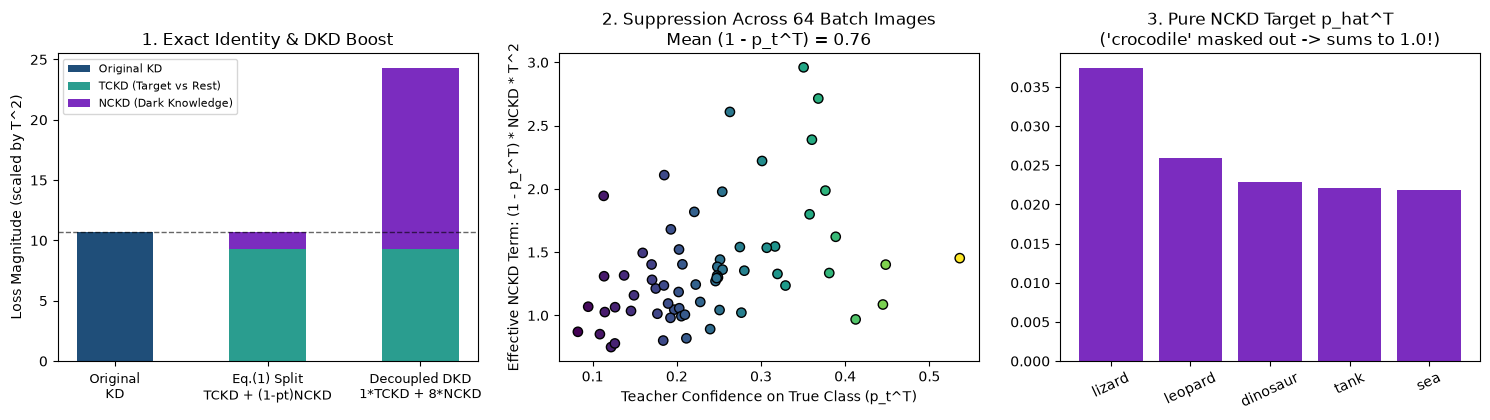

In [38]:
T_val = 4.0
tckd_scaled = (tckd_i.mean() * T_val**2).item()
coupled_nckd_scaled = (((1.0 - pt_teacher) * nckd_i).mean() * T_val**2).item()
dkd_nckd_scaled = (8.0 * nckd_i.mean() * T_val**2).item()

pt_np = pt_teacher.detach().cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Panel 1: Stacked Bar Comparison (KD == Coupled Split vs DKD)
labels_bar = ["Original\nKD", "Eq.(1) Split\nTCKD + (1-pt)NCKD", "Decoupled DKD\n1*TCKD + 8*NCKD"]
# Bar 1: solid KD; Bar 2 & 3: green TCKD bottom + purple NCKD top
axes[0].bar([0], [val_kd.item()], color="#1f4e79", width=0.5, label="Original KD")
axes[0].bar([1, 2], [tckd_scaled, tckd_scaled], color="#2a9d8f", width=0.5, label="TCKD (Target vs Rest)")
axes[0].bar([1, 2], [coupled_nckd_scaled, dkd_nckd_scaled], bottom=[tckd_scaled, tckd_scaled], color="#7b2cbf", width=0.5, label="NCKD (Dark Knowledge)")
axes[0].axhline(val_kd.item(), color="k", linestyle="--", linewidth=1, alpha=0.6)
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(labels_bar, fontsize=9)
axes[0].set_ylabel("Loss Magnitude (scaled by T^2)")
axes[0].set_title("1. Exact Identity & DKD Boost")
axes[0].legend(fontsize=8)

# Panel 2: How Classical KD Suppresses NCKD on Confident Images (64 batch samples)
effective_nckd_i = ((1.0 - pt_teacher) * nckd_i * T_val**2).detach().cpu().numpy()
axes[1].scatter(pt_np, effective_nckd_i, c=pt_np, cmap="viridis", edgecolors="k", s=45)
axes[1].set_xlabel("Teacher Confidence on True Class (p_t^T)")
axes[1].set_ylabel("Effective NCKD Term: (1 - p_t^T) * NCKD * T^2")
axes[1].set_title(f"2. Suppression Across 64 Batch Images\nMean (1 - p_t^T) = {(1 - pt_np).mean():.2f}")

# Panel 3: Image 0 ('crocodile') Non-Target Conditional p_hat^T (True Class Masked Out!)
gt_mask_0 = torch.zeros(100, dtype=torch.bool, device=DEVICE)
gt_mask_0[batch_y[0]] = True
p_hat_t0 = F.softmax((batch_logits_t[0] / T_val).masked_fill(gt_mask_0, -1000.0), dim=0).cpu().numpy()
top5_nontarget = p_hat_t0.argsort()[::-1][:5]

axes[2].bar([fine_names[i] for i in top5_nontarget], p_hat_t0[top5_nontarget], color="#7b2cbf")
axes[2].set_title(f"3. Pure NCKD Target p_hat^T\n('{fine_names[int(batch_y[0])]}' masked out -> sums to 1.0!)")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [39]:
def compute_student_loss(
    mode: str,
    logits_s: torch.Tensor,
    targets: torch.Tensor,
    logits_t: torch.Tensor | None = None,
    epoch: int = 20,
    alpha: float = 1.0,
    beta: float = 8.0,
    T: float = 4.0,
    warmup_epochs: int = 20,
) -> tuple[torch.Tensor, float, float]:
    """Returns (total_loss_tensor, ce_float, distill_float) for any of the 5 experiment modes."""
    loss_ce = F.cross_entropy(logits_s, targets)

    if mode == "ce":
        loss_distill = torch.zeros_like(loss_ce)
    elif mode == "kd":
        loss_distill = kd_loss(logits_s, logits_t, T=T)
    else:
        w = min(epoch / warmup_epochs, 1.0) if warmup_epochs > 0 else 1.0
        eff_alpha = 0.0 if mode == "nckd_only" else alpha
        eff_beta  = 0.0 if mode == "tckd_only" else beta
        loss_distill = w * dkd_loss(logits_s, logits_t, targets, alpha=eff_alpha, beta=eff_beta, T=T)

    total = loss_ce + loss_distill
    return total, loss_ce.item(), loss_distill.item()


# Sanity check: inspect all 5 experiment modes on our 64-image batch (at full strength, epoch=20)
print(f"{'Mode':12s} | {'CE Loss':>9s} | {'Distill Loss':>12s} | {'Total Loss':>10s}")
print("-" * 52)
for m in ["ce", "kd", "tckd_only", "nckd_only", "dkd"]:
    tot, ce_v, dist_v = compute_student_loss(m, batch_logits_s, batch_y, batch_logits_t, epoch=20)
    print(f"{m:12s} | {ce_v:9.4f} | {dist_v:12.4f} | {tot.item():10.4f}")

Mode         |   CE Loss | Distill Loss | Total Loss
----------------------------------------------------
ce           |    4.6145 |       0.0000 |     4.6145
kd           |    4.6145 |      10.6828 |    15.2973
tckd_only    |    4.6145 |       9.3069 |    13.9214
nckd_only    |    4.6145 |      14.9866 |    19.6011
dkd          |    4.6145 |      24.2934 |    28.9080


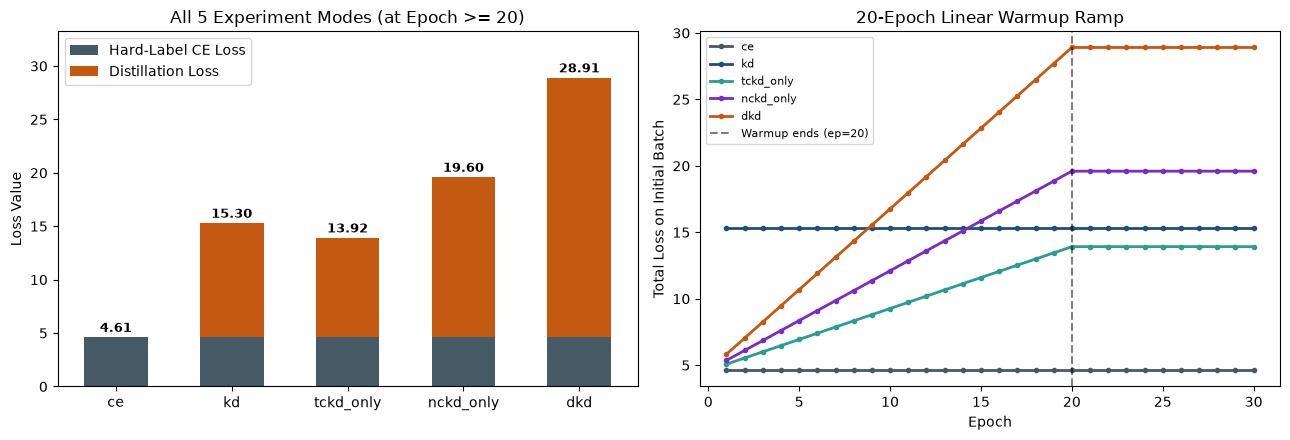

In [40]:
modes_list = ["ce", "kd", "tckd_only", "nckd_only", "dkd"]
ce_vals, dist_vals, tot_vals = [], [], []

for m in modes_list:
    tot, ce_v, dist_v = compute_student_loss(m, batch_logits_s, batch_y, batch_logits_t, epoch=20)
    ce_vals.append(ce_v)
    dist_vals.append(dist_v)
    tot_vals.append(tot.item())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: Stacked Bar of CE + Distillation across all 5 modes
x_idx = np.arange(len(modes_list))
axes[0].bar(x_idx, ce_vals, width=0.55, label="Hard-Label CE Loss", color="#455a64")
axes[0].bar(x_idx, dist_vals, bottom=ce_vals, width=0.55, label="Distillation Loss", color="#c45911")

for i, total in enumerate(tot_vals):
    axes[0].text(i, total + 0.5, f"{total:.2f}", ha="center", fontsize=9, fontweight="bold")

axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(modes_list, fontsize=10)
axes[0].set_ylim(0, max(tot_vals) * 1.15)
axes[0].set_ylabel("Loss Value")
axes[0].set_title("All 5 Experiment Modes (at Epoch >= 20)")
axes[0].legend()

# Right: Why 20-Epoch Warmup Matters (Total Loss from Epoch 1 -> 30)
ep_range = np.arange(1, 31)
for m, color in [("ce", "#455a64"), ("kd", "#1f4e79"), ("tckd_only", "#2a9d8f"), ("nckd_only", "#7b2cbf"), ("dkd", "#c45911")]:
    curve = [compute_student_loss(m, batch_logits_s, batch_y, batch_logits_t, epoch=int(ep))[0].item() for ep in ep_range]
    axes[1].plot(ep_range, curve, marker="o", markersize=3, linewidth=2, label=m, color=color)

axes[1].axvline(20, color="k", linestyle="--", alpha=0.5, label="Warmup ends (ep=20)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Total Loss on Initial Batch")
axes[1].set_title("20-Epoch Linear Warmup Ramp")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
def adjust_lr(optimizer: torch.optim.Optimizer, epoch: int, base_lr: float = 0.05) -> float:
    """Drop LR by 10x at epochs 150, 180, and 210 (exact DKD CIFAR-100 schedule)."""
    drops = sum(1 for milestone in (150, 180, 210) if epoch >= milestone) #drops: number of times the learning rate is dropped
    lr = base_lr * (0.1 ** drops) #lr: learning rate
    for group in optimizer.param_groups: #group: group of parameters
        group["lr"] = lr #set the learning rate for the group
    return lr #return the learning rate

In [ ]:
def train_one_epoch(
    student: nn.Module, #student: student model
    teacher_model: nn.Module | None,
    optimizer: torch.optim.Optimizer,
    loader: DataLoader, #loader: data loader
    mode: str, #mode: mode of the training
    epoch: int, #epoch: epoch
    T: float = 4.0, #T: temperature
    max_batches: int | None = None, #max_batches: maximum number of batches
) -> dict[str, float]: #return the training loss, cross entropy, distillation loss, accuracy, and batch time
    student.train() #set the student to training mode
    if teacher_model is not None: #if the teacher model is not None, set the teacher to evaluation mode
        teacher_model.eval() #set the teacher to evaluation mode
    tot_loss, tot_ce, tot_dist, tot_correct, tot_n = 0.0, 0.0, 0.0, 0, 0 #tot_loss: total loss, tot_ce: total cross entropy, tot_dist: total distillation loss, tot_correct: total correct, tot_n: total number of samples
    batch_ms_list = [] #batch_ms_list: list of batch times
    for b_idx, (images, labels) in enumerate(loader): #b_idx: batch index, images: images, labels: labels
        if max_batches is not None and b_idx >= max_batches: #if the maximum number of batches is not None and the batch index is greater than the maximum number of batches, break
            break
        t0 = time.perf_counter() #t0: time of the batch
        images, labels = images.to(DEVICE), labels.to(DEVICE) #images: images, labels: labels
        # 1. Forward pass: Student tracks gradients; Teacher is frozen under no_grad()
        logits_s = student(images) #logits_s: logits of the student
        logits_t = None #logits_t: logits of the teacher
        if mode != "ce": #if the mode is not "ce", set the teacher to evaluation mode
            with torch.no_grad(): #with torch.no_grad(), the teacher is frozen
                logits_t = teacher_model(images) #logits_t: logits of the teacher
        # 2. Compute loss + backpropagate into Student ONLY
        loss, ce_val, dist_val = compute_student_loss(mode, logits_s, labels, logits_t, epoch=epoch, T=T) #loss: loss, ce_val: cross entropy value, dist_val: distillation value
        optimizer.zero_grad(set_to_none=True) #set the gradients to None
        loss.backward() #backpropagate the loss
        optimizer.step() #step the optimizer
        if DEVICE.type == "cuda": #if the device is cuda, synchronize the cuda
            torch.cuda.synchronize()
        elif DEVICE.type == "mps": #if the device is mps, synchronize the mps
            torch.mps.synchronize()
        batch_ms_list.append((time.perf_counter() - t0) * 1000.0) #append the batch time to the list
        bs = labels.size(0) #bs: batch size
        tot_loss += loss.item() * bs #total loss += loss * batch size
        tot_ce += ce_val * bs #total cross entropy += cross entropy value * batch size
        tot_dist += dist_val * bs #total distillation += distillation value * batch size
        tot_correct += (logits_s.argmax(dim=1) == labels).sum().item() #total correct += number of correct predictions
        tot_n += bs #total number of samples += batch size
    return {
        "train_loss": tot_loss / tot_n, #train loss = total loss / total number of samples
        "train_ce": tot_ce / tot_n, #train cross entropy = total cross entropy / total number of samples
        "train_dist": tot_dist / tot_n, #train distillation = total distillation / total number of samples
        "train_acc": 100.0 * tot_correct / tot_n, #train accuracy = 100 * total correct / total number of samples   
        "batch_ms": float(np.mean(batch_ms_list)), #batch time = average batch time
    }
print("LR milestones check:", {ep: round(0.05 * (0.1 ** sum(ep >= m for m in (150, 180, 210))), 6) for ep in [1, 150, 180, 210]}) #print the learning rate milestones


LR milestones check: {1: 0.05, 150: 0.005, 180: 0.0005, 210: 5e-05}


In [ ]:
import json

OUTPUT_ROOT = PROJECT_ROOT / "outputs_scratch"

#Evaluate the student model
@torch.no_grad()
def eval_student(model: nn.Module, loader: DataLoader, max_batches: int | None = None) -> tuple[float, float]:
    model.eval() #set the model to evaluation mode
    tot_loss, tot_corr, tot_n = 0.0, 0, 0 #tot_loss: total loss, tot_corr: total correct, tot_n: total number of samples
    for b_i, (x, y) in enumerate(loader): #b_i: batch index, x: images, y: labels
        if max_batches is not None and b_i >= max_batches: #if the maximum number of batches is not None and the batch index is greater than the maximum number of batches, break
            break
        x, y = x.to(DEVICE), y.to(DEVICE) #x: images, y: labels
        logits = model(x) #logits: logits of the model
        tot_loss += F.cross_entropy(logits, y).item() * y.size(0) #total loss += cross entropy * batch size
        tot_corr += (logits.argmax(dim=1) == y).sum().item() #total correct += number of correct predictions
        tot_n += y.size(0) #total number of samples += batch size
    return tot_loss / tot_n, 100.0 * tot_corr / tot_n #return the total loss and the total accuracy

#Run the experiment
def run_experiment(
    run_name: str,
    mode: str,
    T: float = 4.0,
    epochs: int = 240,
    max_batches: int | None = None,
    resume: bool = True,
) -> list[dict]:
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    out_dir = OUTPUT_ROOT / run_name
    out_dir.mkdir(parents=True, exist_ok=True)
    last_ckpt, best_ckpt = out_dir / "ckpt_last.pth", out_dir / "ckpt_best.pth" #last_ckpt: last checkpoint, best_ckpt: best checkpoint

    student = StudentResNet8x4().to(DEVICE) #student: student model
    optimizer = torch.optim.SGD(student.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4) #optimizer: optimizer for the student model

    start_ep, best_acc, history = 1, 0.0, [] #start_ep: start epoch, best_acc: best accuracy, history: history of the experiment
    if resume and last_ckpt.exists():
        saved = torch.load(last_ckpt, map_location=DEVICE, weights_only=False) #saved: saved model
        student.load_state_dict(saved["model"]) #load the model
        optimizer.load_state_dict(saved["optimizer"]) #load the optimizer   #saved["epoch"]: epoch, saved["best_acc"]: best accuracy, saved["history"]: history of the experiment
        start_ep, best_acc, history = saved["epoch"] + 1, saved["best_acc"], saved["history"] #start_ep: start epoch, best_acc: best accuracy, history: history of the experiment
        print(f"[{run_name}] Resumed at epoch {start_ep} (best={best_acc:.2f}%)") #print the resumed epoch and best accuracy

    print(f"=== {run_name} | mode={mode} | T={T} | epochs={epochs} ===") #print the run name, mode, temperature, and number of epochs
    for ep in range(start_ep, epochs + 1):
        lr = adjust_lr(optimizer, ep, base_lr=0.05) #adjust the learning rate
        tr = train_one_epoch(student, teacher, optimizer, train_loader, mode=mode, epoch=ep, T=T, max_batches=max_batches) #train the model
        test_loss, test_acc = eval_student(student, test_loader, max_batches=max_batches) #evaluate the model

        is_best = test_acc >= best_acc #check if the test accuracy is better than the best accuracy
        best_acc = max(best_acc, test_acc) #update the best accuracy    

        row = {"epoch": ep, "lr": lr, **tr, "test_loss": test_loss, "test_acc": test_acc, "best_acc": best_acc} #row: row of the history
        history.append(row) #append the row to the history

        payload = {"epoch": ep, "best_acc": best_acc, "mode": mode, "T": T, "model": student.state_dict(), "optimizer": optimizer.state_dict(), "history": history} #payload: payload of the model
        torch.save(payload, last_ckpt) #save the model
        if is_best:
            torch.save(payload, best_ckpt) #save the best model
        (out_dir / "history.json").write_text(json.dumps(history, indent=2)) #save the history

        if ep == 1 or ep % 10 == 0 or ep == epochs or FAST_DEV_RUN: #print the epoch, learning rate, cross entropy, training accuracy, test accuracy, and batch time    
            print(f"Ep {ep:03d}/{epochs:03d} | lr={lr:.5f} | CE={tr['train_ce']:.3f} | tr_acc={tr['train_acc']:.1f}% | te_acc={test_acc:.2f}% | {tr['batch_ms']:.1f}ms/b") #print the epoch, learning rate, cross entropy, training accuracy, test accuracy, and batch time    

    return history

=== smoke_dkd_T4 | mode=dkd | T=4.0 | epochs=3 ===
Ep 001/003 | lr=0.05000 | CE=4.510 | tr_acc=3.2% | te_acc=3.94% | 141.8ms/b
Ep 002/003 | lr=0.05000 | CE=4.325 | tr_acc=5.0% | te_acc=4.81% | 114.0ms/b
Ep 003/003 | lr=0.05000 | CE=4.198 | tr_acc=6.6% | te_acc=4.56% | 114.2ms/b


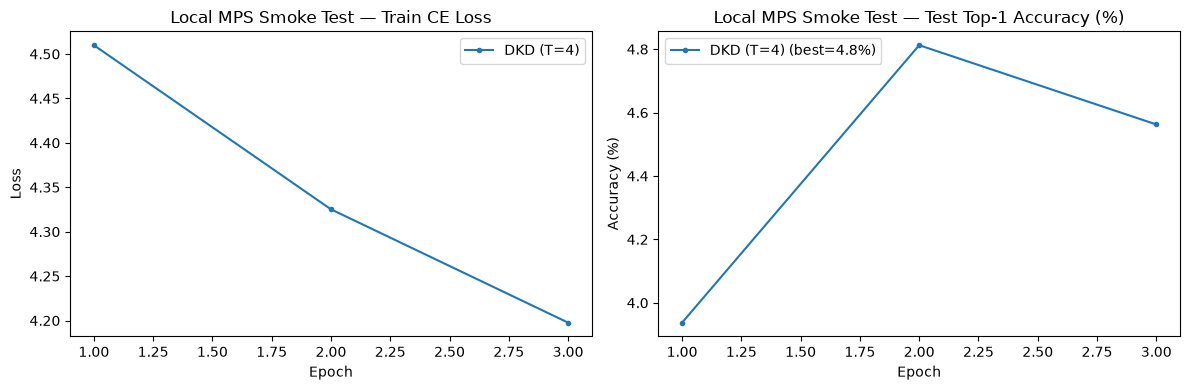

In [ ]:
def plot_history(histories: dict[str, list[dict]], title: str = "Training Curves"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, hist in histories.items():
        eps = [r["epoch"] for r in hist]
        axes[0].plot(eps, [r["train_ce"] for r in hist], marker="o", markersize=3, label=name)
        axes[1].plot(eps, [r["test_acc"] for r in hist], marker="o", markersize=3, label=f"{name} (best={hist[-1]['best_acc']:.1f}%)")

    axes[0].set_title(f"{title} — Train CE Loss"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
    axes[1].set_title(f"{title} — Test Top-1 Accuracy (%)"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend()
    plt.tight_layout()
    plt.show()


# Smoke-test 3 quick epochs of DKD right now on Mac MPS!
dev_epochs  = 3 if FAST_DEV_RUN else 240
dev_batches = 25 if FAST_DEV_RUN else None

if FAST_DEV_RUN:
    smoke_hist = run_experiment("smoke_dkd_T4", mode="dkd", T=4.0, epochs=3, max_batches=25, resume=False)
    plot_history({"DKD (T=4)": smoke_hist}, title="Local MPS Smoke Test")

### Computational Throughput & Compression Benchmark
This cell benchmarks training-time step cost alongside deployment-time model compression:

Training time (ms/batch): Proves dkd adds zero noticeable overhead over kd because both run the exact same 1 Student + 1 Teacher forward pass (0 extra parameters!).
Deployment inference speed (ms/image) & size (MB): Shows why distilling into StudentResNet8x4 matters in production (6.03× smaller checkpoint and ~3× faster inference than the Teacher!).

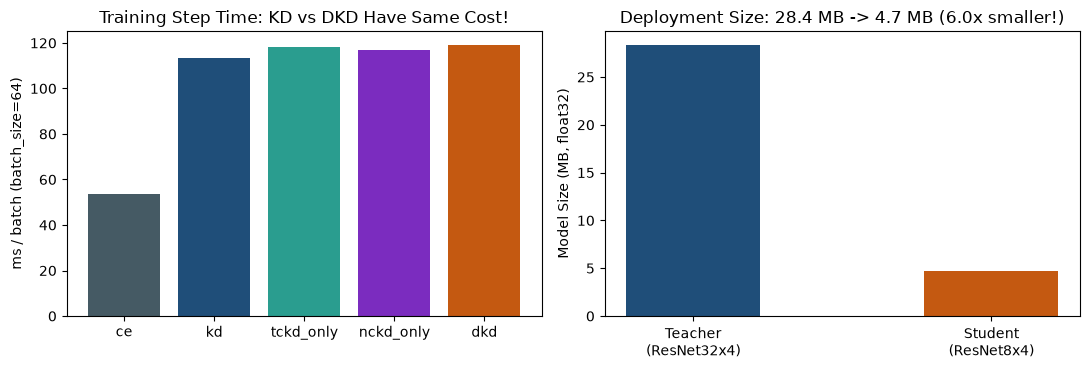

  ce         : 53.65 ms/batch
  kd         : 113.16 ms/batch
  tckd_only  : 118.24 ms/batch
  nckd_only  : 117.07 ms/batch
  dkd        : 119.14 ms/batch


In [45]:
def benchmark_speed() -> dict[str, float]:
    s_bench = StudentResNet8x4().to(DEVICE).train()
    opt = torch.optim.SGD(s_bench.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
    x_b = torch.randn(64, 3, 32, 32, device=DEVICE)
    y_b = torch.randint(0, 100, (64,), device=DEVICE)

    timings = {}
    for m in ["ce", "kd", "tckd_only", "nckd_only", "dkd"]:
        times = []
        for step in range(15):  # 5 warmup steps + 10 timed steps
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            elif DEVICE.type == "mps": torch.mps.synchronize()
            t0 = time.perf_counter()

            lg_s = s_bench(x_b)
            lg_t = teacher(x_b) if m != "ce" else None
            loss, _, _ = compute_student_loss(m, lg_s, y_b, lg_t, epoch=20)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()

            if DEVICE.type == "cuda": torch.cuda.synchronize()
            elif DEVICE.type == "mps": torch.mps.synchronize()
            if step >= 5:
                times.append((time.perf_counter() - t0) * 1000.0)
        timings[m] = float(np.mean(times))
    return timings


step_ms = benchmark_speed()
s_mb = sum(p.numel() * 4 for p in student_untrained.parameters()) / (1024 ** 2)
t_mb = sum(p.numel() * 4 for p in teacher.parameters()) / (1024 ** 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(list(step_ms.keys()), list(step_ms.values()), color=["#455a64", "#1f4e79", "#2a9d8f", "#7b2cbf", "#c45911"])
axes[0].set_ylabel("ms / batch (batch_size=64)")
axes[0].set_title("Training Step Time: KD vs DKD Have Same Cost!")

axes[1].bar(["Teacher\n(ResNet32x4)", "Student\n(ResNet8x4)"], [t_mb, s_mb], color=["#1f4e79", "#c45911"], width=0.45)
axes[1].set_ylabel("Model Size (MB, float32)")
axes[1].set_title(f"Deployment Size: {t_mb:.1f} MB -> {s_mb:.1f} MB ({t_mb/s_mb:.1f}x smaller!)")
plt.tight_layout()
plt.show()

for k, v in step_ms.items():
    print(f"  {k:10s} : {v:.2f} ms/batch")

## Stage 6: Full Experiment Suite — Paper Reproduction + Our 3 Custom Studies

Every run below calls `run_experiment(...)` with the **exact same `SEED = 42`**, initial `StudentResNet8x4` weights, CIFAR-100 data splits, and 240-epoch SGD schedule (`lr = 0.05` dropped by $10\times$ at epochs `[150, 180, 210]`, `batch_size = 64`, 20-epoch linear warmup on DKD modes). **Only the loss formulation or temperature $T$ changes.**

Note that **`dkd_T4` (`mode="dkd"`, $T=4.0$)** and **`kd_T4` (`mode="kd"`, $T=4.0$)** are trained **once** and shared across comparisons so zero GPU compute is wasted:

1. **Paper Reproduction (`ResNet32x4 -> ResNet8x4`):**
   - `ce`: Plain `ResNet8x4` Student trained on hard one-hot labels only (no Teacher).
   - `kd_T4`: Classical Hinton KD ($T = 4.0$), where non-target dark knowledge is coupled to $(1 - p_t^T)$.
   - `dkd_T4`: Proposed Decoupled KD ($\alpha = 1.0, \beta = 8.0, T = 4.0$), targeting the paper's **76.32%** ($\pm 1\%$).

2. **Study 1 — Decoupled Component Ablation (`TCKD` vs. `NCKD`):**
   - *Research Question:* Which decoupled term actually drives the accuracy gain, and what happens if we remove either one?
   - `tckd_only_T4` ($\alpha = 1.0, \beta = 0.0$): Removes dark knowledge completely — tests target-confidence transfer alone.
   - `nckd_only_T4` ($\alpha = 0.0, \beta = 8.0$): Removes binary target-confidence transfer — tests pure 99-class dark knowledge alone.

3. **Study 2 — Temperature Robustness & Asymptotic MSE Limit Sweep:**
   - *Research Question:* How sensitive is DKD vs. Classical KD across sharp ($T=1$), standard ($T=4$), high ($T=10$), and asymptotic ($T=100$) temperatures?
   - `dkd_T1`, `dkd_T4`, `dkd_T10`, `dkd_T100` vs. `kd_T1`, `kd_T4`, `kd_T10`.

> **Running on Google Colab GPU:** Set `FAST_DEV_RUN = False` in Cell 1; `resume=True` automatically skips completed 240-epoch runs on Google Drive and picks up any interrupted run from its last saved epoch.


In [47]:
import os
import zipfile

# On Google Colab: mount Drive and point OUTPUT_ROOT to a brand-new 'DKD_Final_Training' folder!
IN_COLAB = "COLAB_GPU" in os.environ or Path("/content").exists()
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/DKD_Final_Training")
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Final checkpoints & logs directory: {OUTPUT_ROOT}")

Final checkpoints & logs directory: /Users/sufyan.siddiqui/ML-Project/outputs_scratch


=== ce | mode=ce | T=4.0 | epochs=2 ===
Ep 001/002 | lr=0.05000 | CE=4.575 | tr_acc=3.3% | te_acc=2.81% | 55.4ms/b
Ep 002/002 | lr=0.05000 | CE=4.483 | tr_acc=3.6% | te_acc=3.75% | 52.7ms/b
=== kd_T4 | mode=kd | T=4.0 | epochs=2 ===
Ep 001/002 | lr=0.05000 | CE=4.643 | tr_acc=2.9% | te_acc=2.60% | 115.6ms/b
Ep 002/002 | lr=0.05000 | CE=4.522 | tr_acc=3.4% | te_acc=4.27% | 117.0ms/b
=== dkd_T4 | mode=dkd | T=4.0 | epochs=2 ===
Ep 001/002 | lr=0.05000 | CE=4.548 | tr_acc=3.6% | te_acc=3.02% | 114.4ms/b
Ep 002/002 | lr=0.05000 | CE=4.396 | tr_acc=3.9% | te_acc=4.06% | 113.7ms/b
=== tckd_only_T4 | mode=tckd_only | T=4.0 | epochs=2 ===
Ep 001/002 | lr=0.05000 | CE=4.580 | tr_acc=3.3% | te_acc=2.92% | 114.1ms/b
Ep 002/002 | lr=0.05000 | CE=4.500 | tr_acc=3.1% | te_acc=3.33% | 114.2ms/b
=== nckd_only_T4 | mode=nckd_only | T=4.0 | epochs=2 ===
Ep 001/002 | lr=0.05000 | CE=4.544 | tr_acc=3.5% | te_acc=3.12% | 114.7ms/b
Ep 002/002 | lr=0.05000 | CE=4.381 | tr_acc=4.1% | te_acc=4.06% | 122.2ms/b


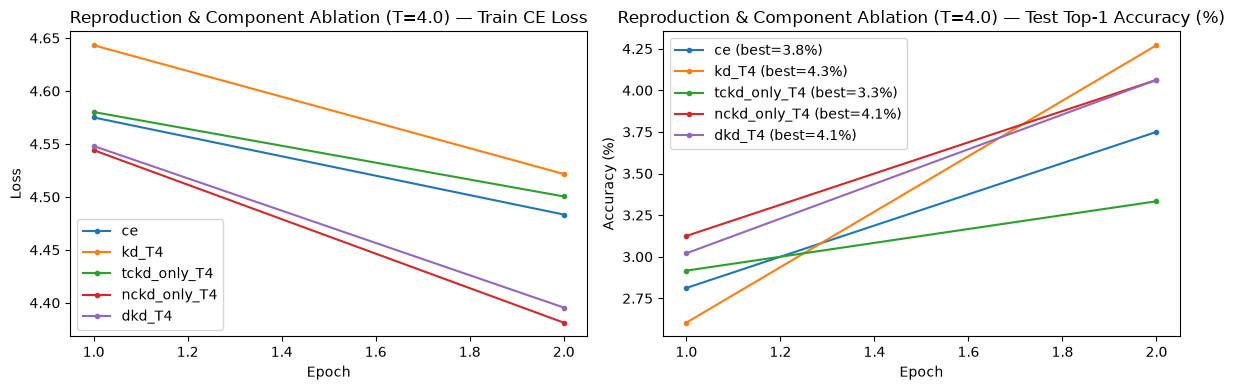

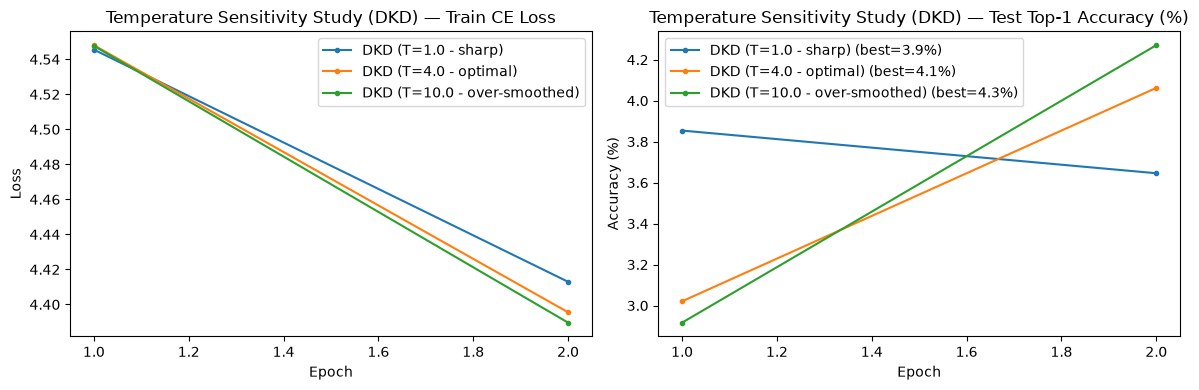


Run Name        | Mode       |  Temp | Best Test Top-1
-------------------------------------------------------
ce              | ce         |   4.0 |           3.75%
kd_T4           | kd         |   4.0 |           4.27%
dkd_T4          | dkd        |   4.0 |           4.06%
tckd_only_T4    | tckd_only  |   4.0 |           3.33%
nckd_only_T4    | nckd_only  |   4.0 |           4.06%
dkd_T1          | dkd        |   1.0 |           3.85%
dkd_T10         | dkd        |  10.0 |           4.27%


In [ ]:
RUN_EPOCHS  = 2 if FAST_DEV_RUN else 240
RUN_BATCHES = 15 if FAST_DEV_RUN else None

EXPERIMENT_PLAN = [
    # --- 1. Paper Reproduction ---
    ("dkd_T4",       "dkd",       4.0),
    ("ce",           "ce",        4.0),
    ("kd_T4",        "kd",        4.0),
    # --- 2A. Decoupled Component Ablation ---
    ("tckd_only_T4", "tckd_only", 4.0),
    ("nckd_only_T4", "nckd_only", 4.0),
    # --- 2B. DKD vs Classical KD Temperature & Asymptotic Sweep ---
    ("dkd_T1",       "dkd",       1.0),
    ("dkd_T10",      "dkd",      10.0),
    ("kd_T1",        "kd",        1.0),
    ("kd_T10",       "kd",      10.0),
    ("dkd_T100",     "dkd",     100.0),
]

all_results: dict[str, list[dict]] = {}
for run_name, mode_name, temp_val in EXPERIMENT_PLAN:
    all_results[run_name] = run_experiment(
        run_name=run_name,
        mode=mode_name,
        T=temp_val,
        epochs=RUN_EPOCHS,
        max_batches=RUN_BATCHES,
        resume=not FAST_DEV_RUN,
    )

# Plot 1: Reproduction + Component Ablation Curves (T = 4.0)
plot_history(
    {k: all_results[k] for k in ["ce", "kd_T4", "tckd_only_T4", "nckd_only_T4", "dkd_T4"]},
    title="Reproduction & Component Ablation (T=4.0)",
)

# Plot 2: DKD Temperature Sweep (T = 1.0, 4.0, 10.0, 100.0)
plot_history(
    {
        "DKD (T=1.0)":   all_results["dkd_T1"],
        "DKD (T=4.0)":   all_results["dkd_T4"],
        "DKD (T=10.0)":  all_results["dkd_T10"],
        "DKD (T=100.0)": all_results["dkd_T100"],
    },
    title="DKD Temperature & Asymptotic MSE Limit Sweep",
)

# Plot 3: Classical KD vs DKD Across Temperatures (T = 1.0, 4.0, 10.0)
plot_history(
    {
        "KD (T=1.0)":  all_results["kd_T1"],
        "KD (T=4.0)":  all_results["kd_T4"],
        "KD (T=10.0)": all_results["kd_T10"],
        "DKD (T=1.0)": all_results["dkd_T1"],
        "DKD (T=4.0)": all_results["dkd_T4"],
        "DKD (T=10.0)": all_results["dkd_T10"],
    },
    title="Classical KD vs. DKD Temperature Robustness (T = 1, 4, 10)",
)

# Summary Leaderboard Table
print(f"\n{'Run Name':15s} | {'Mode':10s} | {'Temp':>5s} | {'Best Test Top-1':>15s}")
print("-" * 55)
for run_name, mode_name, temp_val in EXPERIMENT_PLAN:
    best = all_results[run_name][-1]["best_acc"]
    print(f"{run_name:15s} | {mode_name:10s} | {temp_val:5.1f} | {best:14.2f}%")

In [48]:
export_zip = OUTPUT_ROOT / "dkd_final_training_results.zip"
with zipfile.ZipFile(export_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for item in sorted(OUTPUT_ROOT.rglob("*")):
        if item.is_file() and item.name in ("ckpt_best.pth", "history.json"):
            zf.write(item, arcname=str(item.relative_to(OUTPUT_ROOT)))

print(f"Created archive: {export_zip} ({export_zip.stat().st_size / (1024**2):.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(export_zip))

Created archive: /Users/sufyan.siddiqui/ML-Project/outputs_scratch/dkd_final_training_results.zip (69.7 MB)


Best Checkpoint Epoch : 234 / 240
Our Best Test Top-1   : 76.05% (vs. Paper 5-run mean: 76.32%)


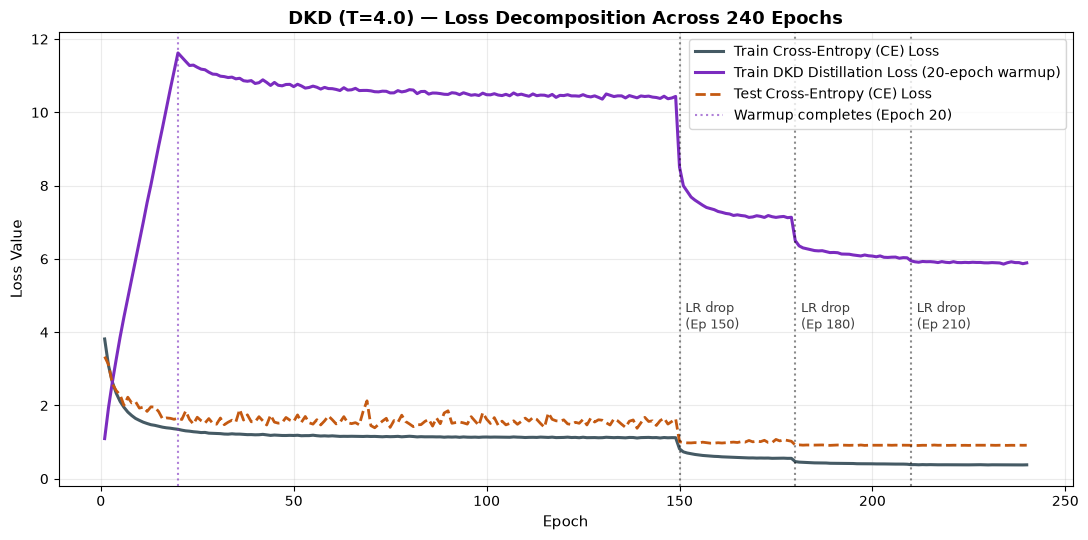

In [50]:
import json

dkd_dir = PROJECT_ROOT / "outputs_final" / "dkd_T4"
dkd_hist = json.loads((dkd_dir / "history.json").read_text())
dkd_ckpt = torch.load(dkd_dir / "ckpt_best.pth", map_location=DEVICE, weights_only=False)

best_row = max(dkd_hist, key=lambda r: r["test_acc"])
eps = [r["epoch"] for r in dkd_hist]

print(f"Best Checkpoint Epoch : {dkd_ckpt['epoch']} / {len(dkd_hist)}")
print(f"Our Best Test Top-1   : {best_row['test_acc']:.2f}% (vs. Paper 5-run mean: 76.32%)")

plt.figure(figsize=(11, 5.5))
plt.plot(eps, [r["train_ce"] for r in dkd_hist], label="Train Cross-Entropy (CE) Loss", color="#455a64", linewidth=2.2)
plt.plot(eps, [r["train_dist"] for r in dkd_hist], label="Train DKD Distillation Loss (20-epoch warmup)", color="#7b2cbf", linewidth=2.2)
plt.plot(eps, [r["test_loss"] for r in dkd_hist], label="Test Cross-Entropy (CE) Loss", color="#c45911", linestyle="--", linewidth=2.0)

plt.axvline(20, color="#7b2cbf", linestyle=":", alpha=0.6, label="Warmup completes (Epoch 20)")
for m_ep in (150, 180, 210):
    plt.axvline(m_ep, color="black", linestyle=":", alpha=0.45)
    plt.text(m_ep + 1.5, 4.1, f"LR drop\n(Ep {m_ep})", fontsize=9, alpha=0.75)

plt.title("DKD (T=4.0) — Loss Decomposition Across 240 Epochs", fontsize=13, fontweight="bold")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss Value", fontsize=11)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

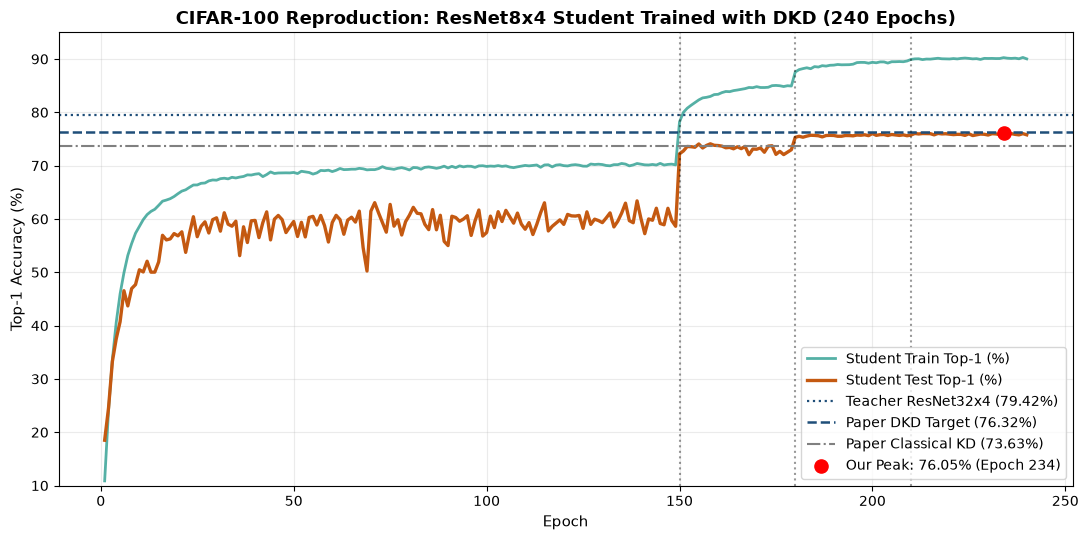

In [51]:
plt.figure(figsize=(11, 5.5))
plt.plot(eps, [r["train_acc"] for r in dkd_hist], label="Student Train Top-1 (%)", color="#2a9d8f", alpha=0.8, linewidth=2.0)
plt.plot(eps, [r["test_acc"] for r in dkd_hist], label="Student Test Top-1 (%)", color="#c45911", linewidth=2.4)

plt.axhline(79.42, color="#1f4e79", linestyle=":", linewidth=1.6, label="Teacher ResNet32x4 (79.42%)")
plt.axhline(76.32, color="#1f4e79", linestyle="--", linewidth=1.8, label="Paper DKD Target (76.32%)")
plt.axhline(73.63, color="gray", linestyle="-.", linewidth=1.5, label="Paper Classical KD (73.63%)")

plt.scatter([best_row["epoch"]], [best_row["test_acc"]], color="red", zorder=6, s=90, label=f"Our Peak: {best_row['test_acc']:.2f}% (Epoch {best_row['epoch']})")

for m_ep in (150, 180, 210):
    plt.axvline(m_ep, color="black", linestyle=":", alpha=0.4)

plt.title("CIFAR-100 Reproduction: ResNet8x4 Student Trained with DKD (240 Epochs)", fontsize=13, fontweight="bold")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Top-1 Accuracy (%)", fontsize=11)
plt.ylim(10, 95)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()

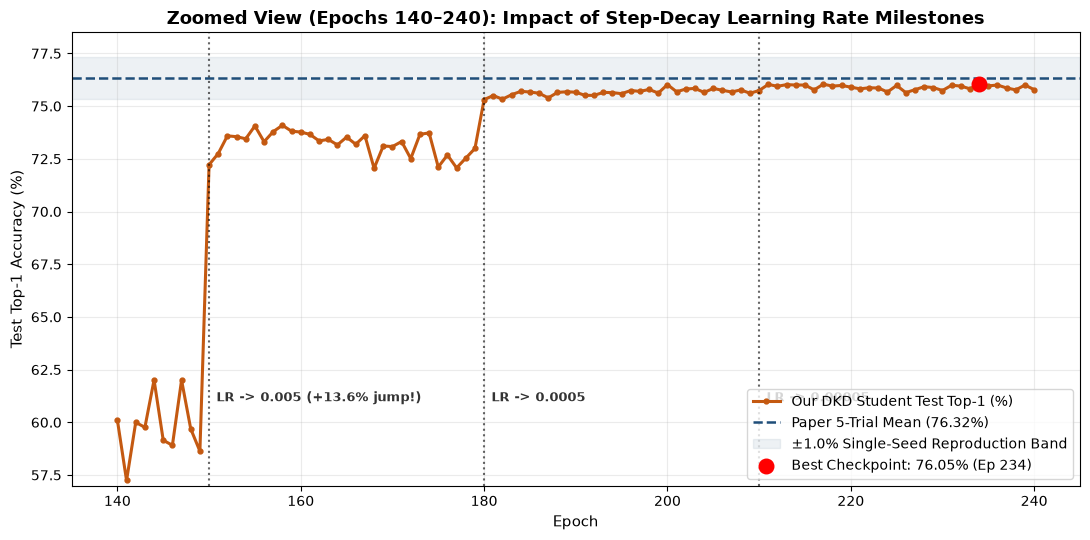

In [52]:
zoom = [r for r in dkd_hist if r["epoch"] >= 140]
z_eps = [r["epoch"] for r in zoom]
z_acc = [r["test_acc"] for r in zoom]

plt.figure(figsize=(11, 5.5))
plt.plot(z_eps, z_acc, color="#c45911", marker="o", markersize=3.5, linewidth=2.2, label="Our DKD Student Test Top-1 (%)")
plt.axhline(76.32, color="#1f4e79", linestyle="--", linewidth=1.8, label="Paper 5-Trial Mean (76.32%)")
plt.axhspan(75.32, 77.32, color="#1f4e79", alpha=0.08, label="±1.0% Single-Seed Reproduction Band")
plt.scatter([best_row["epoch"]], [best_row["test_acc"]], color="red", zorder=6, s=110, label=f"Best Checkpoint: {best_row['test_acc']:.2f}% (Ep {best_row['epoch']})")

for m_ep, lr_str in [(150, "LR -> 0.005 (+13.6% jump!)"), (180, "LR -> 0.0005"), (210, "LR -> 0.00005")]:
    plt.axvline(m_ep, color="black", linestyle=":", alpha=0.6)
    plt.text(m_ep + 0.8, 61.0, lr_str, fontsize=9.5, fontweight="bold", alpha=0.8)

plt.title("Zoomed View (Epochs 140–240): Impact of Step-Decay Learning Rate Milestones", fontsize=13, fontweight="bold")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Test Top-1 Accuracy (%)", fontsize=11)
plt.ylim(57, 78.5)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()